# 08 黑马优购 - 商品列表、商品详情与加入购物车


本篇是微信小程序**项目第 3 天**，承接 07 的分类与搜索，按包内讲义顺序学习“6. 商品列表 → 7. 商品详情 → 8. 加入购物车”。先根据分类或关键词加载商品列表，再开发详情页，最后把商品存入购物车并显示数量徽标。

资料来自[课程网盘](https://pan.baidu.com/s/1crZTQdIZ7OSDkZIpIWkhYw?pwd=1234)的“微信小程序项目/微信小程序项目-资料/day03.rar”，本机下载文件是 `day03 (3).rar`。本篇已读取包内学习目标、25 页 `uni-shop_day3.pdf`、商城 API 文档和 `代码/uni-shop-2` 源码；图片与清晰代码块对照同课程在线讲义的[商品列表](https://applet-base-api-t.itheima.net/docs-uni-shop/6.goodslist.html)、[商品详情](https://applet-base-api-t.itheima.net/docs-uni-shop/7.goodsdetail.html)、[加入购物车](https://applet-base-api-t.itheima.net/docs-uni-shop/8.add2cart.html)。图片直接内嵌在本笔记中。

包内学习目标是：实现下拉刷新与上拉加载更多、使用 `rich-text` 渲染富文本、配置和使用 Vuex、理解侦听器的 `immediate`、把 tabBar 徽标代码抽离为 mixins。本项目沿用 Vue 2 的单文件组件、过滤器和 Vuex 写法。

| 文件 | 本天改动 |
| --- | --- |
| `subpkg/goods_list/goods_list.vue` | 请求参数、商品列表、分页、刷新、详情跳转 |
| `components/my-goods/my-goods.vue` | 商品行组件、默认图片、价格过滤器 |
| `pages.json` | 商品列表的触底距离与下拉刷新配置 |
| `subpkg/goods_detail/goods_detail.vue` | 详情请求、轮播预览、富文本、底部按钮、加入购物车 |
| `store/store.js`、`store/cart.js` | Vuex 实例、购物车数据与持久化、数量统计 |
| `main.js` | 把 Store 挂到 Vue 实例上 |
| `mixins/tabbar-badge.js` | 四个 tabBar 页面共用的数量徽标逻辑 |
| `pages/home`、`pages/cate`、`pages/cart`、`pages/my` | 引入徽标 mixin |

下文片段合并到指定文件的已有节点中，避免重复声明 `data`、`methods` 或 `export default`。课程 Git 命令在商城项目根目录执行；本笔记只展示代码与操作，不执行安装、项目提交或远程推送。


## 一、商品列表：请求条件与页面数据（6.0—6.2）

### 1. 创建 goodslist 分支

以课程项目的 `master` 为基线创建商品列表分支：

```bash
git checkout -b goodslist
```

原讲义 6.0 的命令误写成 `git checkout -b search`，但章节标题、后续提交合并步骤和配套仓库分支均为 `goodslist`，这里按商品列表分支统一。

### 2. 定义请求参数

07 的分类入口向商品列表传 `cid`，搜索历史和首页楼层可以传 `query`。打开 `subpkg/goods_list/goods_list.vue`，在 `data` 中增加 `queryObj`：

```javascript
export default {
  data() {
    return {
      // 请求参数对象
      queryObj: {
        // 查询关键词
        query: '',
        // 商品分类Id
        cid: '',
        // 页码值
        pagenum: 1,
        // 每页显示多少条数据
        pagesize: 10
      }
    }
  }
}
```

| 字段 | 本课初值 | 用途 |
| --- | --- | --- |
| `query` | `''` | 查询关键词 |
| `cid` | `''` | 商品分类 ID |
| `pagenum` | `1` | 从第 1 页开始请求 |
| `pagesize` | `10` | 每页请求 10 条 |

接口为 GET `/api/public/v1/goods/search`，参数对象作为 `uni.$http.get()` 的第二个参数。API 文档的页大小默认值是 20，本课明确传入 10，以本课代码为准。

先在 `onLoad(options)` 中接收页面参数，缺少参数时保留空字符串：

```javascript
export default {
  onLoad(options) {
    // 将页面参数转存到 this.queryObj 对象中
    this.queryObj.query = options.query || ''
    this.queryObj.cid = options.cid || ''
  }
}
```

`options` 是打开页面时 URL 携带的参数；`queryObj` 是提交给列表接口的请求条件。先转存参数，再请求列表，才能使用当前分类或关键词。


### 3. 添加商品列表的编译模式

为方便反复调试，在微信开发者工具的编译模式下拉菜单选择“添加编译模式”：启动页面选 `subpkg/goods_list/goods_list`，启动参数按课件填写 `cid=5`，保存后选择该模式编译，就能直接进入指定分类的商品列表。

启动参数也可以用于核对从上一页传来的条件。课件中的 `cid=5` 是调试示例，应与实际接口数据对应。

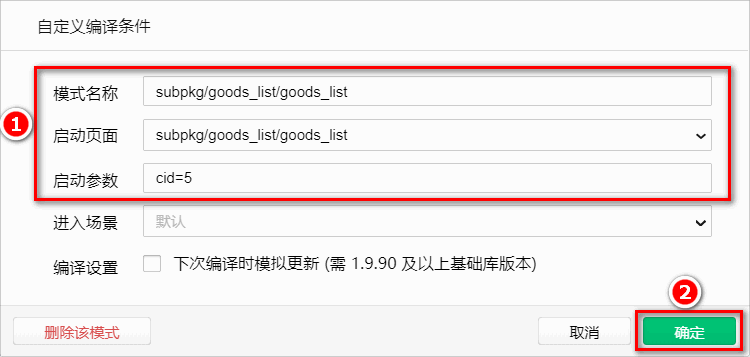


### 4. 获取第一页数据

在同一个 `data` 中增加 `goodsList: []` 和 `total: 0`。`goodsList` 保存当前已展示的商品，`total` 保存接口返回的商品总数，用于判断是否还有下一页。

把参数转存和首次请求合并在同一个 `onLoad` 中：

```javascript
export default {
  onLoad(options) {
    this.queryObj.query = options.query || ''
    this.queryObj.cid = options.cid || ''
    this.getGoodsList()
  }
}
```

在 `methods` 中加入最初版本的 `getGoodsList`：

```javascript
export default {
  methods: {
    // 获取商品列表数据的方法
    async getGoodsList() {
      // 发起请求
      const { data: res } = await uni.$http.get('/api/public/v1/goods/search', this.queryObj)
      if (res.meta.status !== 200) return uni.$showMsg()
      // 为数据赋值
      this.goodsList = res.message.goods
      this.total = res.message.total
    }
  }
}
```

响应正文用 `const { data: res }` 取出。成功后，商品数组来自 `res.message.goods`，总数来自 `res.message.total`；`res.meta.status !== 200` 时统一提示并停止赋值。此时只请求第一页，后面分页时还要把直接赋值改成追加。


## 二、商品行：渲染、组件封装与价格过滤（6.3—6.5）

### 1. 先在页面中渲染商品结构

在 `subpkg/goods_list/goods_list.vue` 中遍历 `goodsList`，每个商品行分为左侧图片和右侧名称、价格：

```html
<template>
  <view>
    <view class="goods-list">
      <block v-for="(goods, i) in goodsList" :key="i">
        <view class="goods-item">
          <!-- 商品左侧图片区域 -->
          <view class="goods-item-left">
            <image :src="goods.goods_small_logo || defaultPic" class="goods-pic"></image>
          </view>
          <!-- 商品右侧信息区域 -->
          <view class="goods-item-right">
            <!-- 商品标题 -->
            <view class="goods-name">{{goods.goods_name}}</view>
            <view class="goods-info-box">
              <!-- 商品价格 -->
              <view class="goods-price">￥{{goods.goods_price}}</view>
            </view>
          </view>
        </view>
      </block>
    </view>
  </view>
</template>
```

`block` 用来组织循环。此时图片读 `goods_small_logo`，名称读 `goods_name`，价格读 `goods_price`；后面会将这一行封装成组件。


### 2. 缺少图片时使用默认图片

某些商品的 `goods_small_logo` 为空。在当前页面 `data` 中增加默认图片地址：

```javascript
export default {
  data() {
    return {
      // 默认的空图片
      defaultPic: 'https://img3.doubanio.com/f/movie/8dd0c794499fe925ae2ae89ee30cd225750457b4/pics/movie/celebrity-default-medium.png'
    }
  }
}
```

把商品图片的 `src` 改为：

```html
<image :src="goods.goods_small_logo || defaultPic" class="goods-pic"></image>
```

逻辑或 `||` 在商品图片地址为空时选择 `defaultPic`。它处理的是地址字段为空的情况；这是课程中的备用图片地址，实际显示仍依赖该图片能被加载。

接着在 `<style lang="scss">` 中加入商品行样式：

```scss
.goods-item {
  display: flex;
  padding: 10px 5px;
  border-bottom: 1px solid #f0f0f0;

  .goods-item-left {
    margin-right: 5px;

    .goods-pic {
      width: 100px;
      height: 100px;
      display: block;
    }
  }

  .goods-item-right {
    display: flex;
    flex-direction: column;
    justify-content: space-between;

    .goods-name {
      font-size: 13px;
    }

    .goods-price {
      font-size: 16px;
      color: #c00000;
    }
  }
}
```

商品行用 Flex 横排，左图为 `100px × 100px` 并设置 `display: block`；右侧纵向排列名称和价格，通过 `space-between` 将二者分布到上下位置。每行有 `10px 5px` 内边距和浅色底边框，名称 `13px`，价格 `16px` 且为红色。


### 3. 创建 my-goods 组件

商品行后续还要在购物车页面复用，因此把它的模板、SCSS 和默认图片移到自定义组件中。

在 HBuilderX 的 `components` 目录上右键“新建组件”，名称为 `my-goods`，选择 SCSS 模板并勾选“创建同名目录”。最终文件是 `components/my-goods/my-goods.vue`。

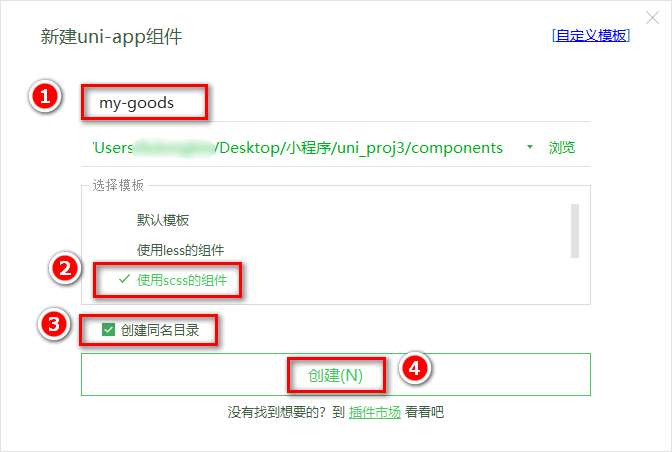


### 4. 组件接收 goods，页面只负责传数据

在 `my-goods.vue` 中使用 `props` 接收商品对象，将默认图片保留在组件自己的 `data` 中。`<script>` 的基本结构如下：

```javascript
export default {
  props: {
    goods: {
      type: Object,
      default: {}
    }
  },
  data() {
    return {
      defaultPic: 'https://img3.doubanio.com/f/movie/8dd0c794499fe925ae2ae89ee30cd225750457b4/pics/movie/celebrity-default-medium.png'
    }
  }
}
```

讲义中的 `defaul` 少了末尾 `t`，配套源码为 `default`，这里按源码保留键名。组件模板继续读取 `goods.goods_name`、`goods.goods_small_logo` 和 `goods.goods_price`，样式随组件一起移入。

在商品列表页面用组件替换整段商品行结构：

```html
<view class="goods-list">
  <block v-for="(item, i) in goodsList" :key="i">
    <!-- 为 my-goods 组件动态绑定 goods 属性的值 -->
    <my-goods :goods="item"></my-goods>
  </block>
</view>
```

`:goods="item"` 把当前商品对象传给组件。默认图片也已随组件移动，列表页不再需要保存 `defaultPic`。组件目录和标签名称遵循 uni-app 的约定，与 07 的 `my-search` 使用方式一致。


### 5. 用过滤器显示两位小数

在 `my-goods.vue` 的 `<script>` 中，与 `data` 平级增加 `filters`：

```javascript
export default {
  filters: {
    // 把数字处理为带两位小数点的数字
    tofixed(num) {
      return Number(num).toFixed(2)
    }
  }
}
```

将价格模板改为：

```html
<!-- 商品价格 -->
<view class="goods-price">￥{{goods.goods_price | tofixed}}</view>
```

`Number(num)` 先转成数字，`toFixed(2)` 返回保留两位小数的字符串。例如价格 `29` 显示成 `￥29.00`。`| tofixed` 是本课 Vue 2 的模板过滤器写法。

下面保留包内 `components/my-goods/my-goods.vue` 的完成版，方便核对封装后的模板、逻辑和样式：

```vue
<template>
  <view class="goods-item">
    <!-- 左侧的盒子 -->
    <view class="goods-item-left">
      <image :src="goods.goods_small_logo || defaultPic" class="goods-pic"></image>
    </view>
    <!-- 右侧的盒子 -->
    <view class="goods-item-right">
      <!-- 商品的名字 -->
      <view class="goods-name">{{goods.goods_name}}</view>
      <view class="goods-info-box">
        <view class="goods-price">￥{{goods.goods_price | tofixed}}</view>
      </view>
    </view>
  </view>
</template>

<script>
  export default {
    props: {
      goods: {
        type: Object,
        default: {}
      }
    },
    data() {
      return {
        // 默认的图片
        defaultPic: 'https://img3.doubanio.com/f/movie/8dd0c794499fe925ae2ae89ee30cd225750457b4/pics/movie/celebrity-default-medium.png'
      };
    },
    filters: {
      tofixed(num) {
        return Number(num).toFixed(2)
      }
    }
  }
</script>

<style lang="scss">
  .goods-item {
    display: flex;
    padding: 10px 5px;
    border-bottom: 1px solid #f0f0f0;

    .goods-item-left {
      margin-right: 5px;

      .goods-pic {
        width: 100px;
        height: 100px;
        display: block;
      }
    }

    .goods-item-right {
      display: flex;
      flex-direction: column;
      justify-content: space-between;

      .goods-name {
        font-size: 13px;
      }

      .goods-info-box {
        .goods-price {
          color: #C00000;
          font-size: 16px;
        }
      }
    }
  }
</style>
```


## 三、商品列表：上拉加载、下拉刷新与详情跳转（6.6—6.9）

### 1. 配置触底距离

在根目录 `pages.json` 中找到 `subPackages` → `root: "subpkg"` → `goods_list/goods_list`，只修改这个页面的 `style`：

```json
{
  "path": "goods_list/goods_list",
  "style": {
    "onReachBottomDistance": 150
  }
}
```

`onReachBottomDistance: 150` 表示距离页面底部 150px 时触发页面触底事件。`onReachBottom` 与 `data`、`methods` 平级，是页面生命周期事件，不放进 `methods`。

最初的触底逻辑先增加页码，再请求数据：

```javascript
export default {
  // 触底的事件
  onReachBottom() {
    // 让页码值自增 +1
    this.queryObj.pagenum += 1
    // 重新获取列表数据
    this.getGoodsList()
  }
}
```

同时把 `getGoodsList()` 的商品赋值改为追加，否则每次只显示新的一页：

```javascript
this.goodsList = [...this.goodsList, ...res.message.goods]
this.total = res.message.total
```

展开运算符先保留旧数组，再追加新页商品。向下滚动后，前面的商品应仍在列表中。


### 2. 用 isloading 防止重复请求

快速滚动可能在上一页请求未完成时再次触底，导致多次请求。原课使用布尔值作为“节流阀”：

1. 在 `data` 中增加 `isloading: false`。
2. `getGoodsList()` 发请求前设为 `true`，收到响应后设为 `false`。
3. `onReachBottom()` 中先检查它；正在请求时立即返回，不继续增加页码。

请求前后的控制位置如下，补在现有 `getGoodsList()` 中：

```javascript
// 获取商品列表数据的方法
async getGoodsList() {
  // ** 打开节流阀
  this.isloading = true
  // 发起请求
  const { data: res } = await uni.$http.get('/api/public/v1/goods/search', this.queryObj)
  // ** 关闭节流阀
  this.isloading = false

  // 省略其它代码...
}
```

触底判断改为：

```javascript
export default {
  // 触底的事件
  onReachBottom() {
    // 判断是否正在请求其它数据，如果是，则不发起额外的请求
    if (this.isloading) return

    this.queryObj.pagenum += 1
    this.getGoodsList()
  }
}
```

这里的“节流阀”是请求期间的状态判断，没有使用定时器；请求完成后才允许下一次触底加载。


### 3. 判断是否已加载全部商品

当 `pagenum × pagesize >= total` 时，已经请求到最后一页。例如总数 23、每页 10，到第 3 页就不再请求第 4 页。

把 `onReachBottom` 更新为原课的最终判断顺序：

```javascript
export default {
  // 触底的事件
  onReachBottom() {
    // 判断是否还有下一页数据
    if (this.queryObj.pagenum * this.queryObj.pagesize >= this.total) return uni.$showMsg('数据加载完毕！')

    // 判断是否正在请求其它数据，如果是，则不发起额外的请求
    if (this.isloading) return

    this.queryObj.pagenum += 1
    this.getGoodsList()
  }
}
```

先判断数据是否加载完毕，再判断是否正在请求，最后递增页码并调用请求。到末尾时提示“数据加载完毕！”。配套源码用英文感叹号，逻辑一致。


### 4. 开启下拉刷新并重置数据

继续修改同一条商品列表页面配置，保留触底距离，新增下拉刷新和刷新区域背景色：

```json
{
  "path": "goods_list/goods_list",
  "style": {
    "onReachBottomDistance": 150,
    "enablePullDownRefresh": true,
    "backgroundColor": "#F8F8F8"
  }
}
```

在 `goods_list.vue` 中，与 `methods` 平级声明 `onPullDownRefresh`：

```javascript
export default {
  // 下拉刷新的事件
  onPullDownRefresh() {
    // 1. 重置关键数据
    this.queryObj.pagenum = 1
    this.total = 0
    this.isloading = false
    this.goodsList = []

    // 2. 重新发起请求
    this.getGoodsList(() => uni.stopPullDownRefresh())
  }
}
```

刷新重新从第一页开始，必须同时重置页码、总数、请求状态和商品数组。筛选条件 `query`、`cid` 保留，仍刷新当前分类或关键词下的数据；如果不清空数组，第一页就会追加到旧列表后面。

为请求方法增加可选回调参数 `cb`，响应返回后关闭加载状态，并按需停止下拉动画：

```javascript
// 获取商品列表数据的方法
async getGoodsList(cb) {
  this.isloading = true
  const { data: res } = await uni.$http.get('/api/public/v1/goods/search', this.queryObj)
  this.isloading = false
  // 只要数据请求完毕，就立即按需调用 cb 回调函数
  cb && cb()

  if (res.meta.status !== 200) return uni.$showMsg()
  this.goodsList = [...this.goodsList, ...res.message.goods]
  this.total = res.message.total
}
```

`cb && cb()` 只在传入回调时调用。首次加载和上拉加载不传回调；下拉刷新传 `() => uni.stopPullDownRefresh()`。回调位于业务状态判断前，因此业务失败时也会先停止刷新动画。这里保留原课的响应处理流程。


### 5. 点击商品打开详情页

为了绑定点击事件，把列表循环外层的 `block` 改为 `view`：

```html
<view class="goods-list">
  <view v-for="(item, i) in goodsList" :key="i" @click="gotoDetail(item)">
    <!-- 为 my-goods 组件动态绑定 goods 属性的值 -->
    <my-goods :goods="item"></my-goods>
  </view>
</view>
```

在 `methods` 中新增：

```javascript
// 点击跳转到商品详情页面
gotoDetail(item) {
  uni.navigateTo({
    url: '/subpkg/goods_detail/goods_detail?goods_id=' + item.goods_id
  })
}
```

目标是普通分包页面，因此使用 `uni.navigateTo()`；通过 `goods_id` 指定当前点击的商品。详情页后面在 `onLoad` 接收该参数。


### 6. 商品列表完成版核对

下面是包内 `subpkg/goods_list/goods_list.vue`。配套源码把当前循环变量命名为 `goods`，讲义部分示例用 `item`；传入对象和读取的 `goods_id` 相同。

```vue
<template>
  <view>
    <view class="goods-list">
      <view v-for="(goods, i) in goodsList" :key="i" @click="gotoDetail(goods)">
        <my-goods :goods="goods"></my-goods>
      </view>
    </view>
  </view>
</template>

<script>
  export default {
    data() {
      return {
        // 请求参数对象
        queryObj: {
          query: '',
          cid: '',
          pagenum: 1,
          pagesize: 10
        },
        goodsList: [],
        total: 0,
        // 节流阀
        isloading: false
      };
    },
    onLoad(options) {
      this.queryObj.query = options.query || ''
      this.queryObj.cid = options.cid || ''

      this.getGoodsList()
    },
    methods: {
      // 获取商品列表数据的方法
      async getGoodsList(cb) {
        // 打开节流阀
        this.isloading = true
        const { data: res } = await uni.$http.get('/api/public/v1/goods/search', this.queryObj)
        // 关闭节流阀
        this.isloading = false
        cb && cb()
        if (res.meta.status !== 200) return uni.$showMsg()

        this.goodsList = [...this.goodsList, ...res.message.goods]
        this.total = res.message.total
      },
      gotoDetail(goods) {
        uni.navigateTo({
          url: '/subpkg/goods_detail/goods_detail?goods_id=' + goods.goods_id
        })
      }
    },
    onReachBottom() {
      if (this.queryObj.pagenum * this.queryObj.pagesize >= this.total) return uni.$showMsg('数据加载完毕!')

      if (this.isloading) return

      // 让页码值自增+1
      this.queryObj.pagenum++
      this.getGoodsList()
    },
    onPullDownRefresh() {
      // 重置关键数据
      this.queryObj.pagenum = 1
      this.total = 0
      this.isloading = false
      this.goodsList = []

      // 重新发起数据请求
      this.getGoodsList(() => uni.stopPullDownRefresh())
    }
  }
</script>

<style lang="scss">

</style>
```

核对时依次检查：首次带条件请求、触底追加下一页、请求过程中不重复加载、末页提示、下拉回到第一页、点击传递当前商品 ID。

完成后，在商城项目根目录提交并合并 `goodslist`：

```bash
git add .
git commit -m "完成了商品列表页面的开发"
git push -u origin goodslist
git checkout master
git merge goodslist
git push
git branch -d goodslist
```

原课在合并到 `master` 后执行 `git push`，再删除已经合并的本地功能分支。


## 四、商品详情：请求、轮播预览与商品信息（7.0—7.3.3）

### 1. 创建 goodsdetail 分支

商品列表分支合并后，从 `master` 创建详情分支：

```bash
git checkout -b goodsdetail
```

详情文件沿用 06 中已创建的 `subpkg/goods_detail/goods_detail.vue`。


### 2. 添加详情页的编译模式

在微信开发者工具的编译模式下拉菜单中，选择“添加编译模式”：

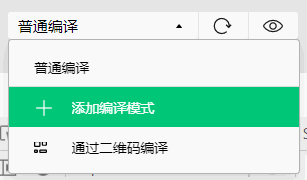


启动页面选择 `subpkg/goods_detail/goods_detail`，启动参数按课件填写 `goods_id=395`，点击“确定”。这样调试时可以直接进入这个商品的详情页。

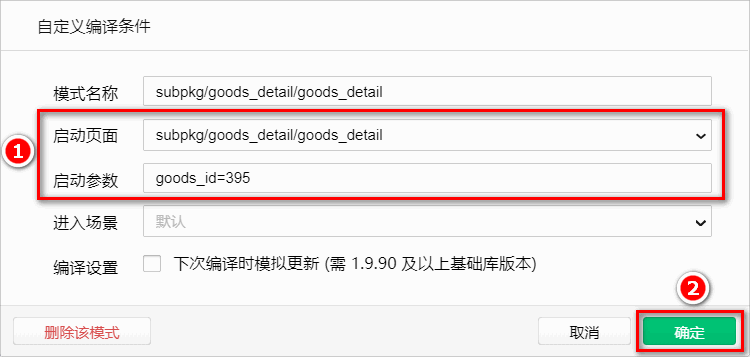


### 3. 根据 goods_id 获取详情

在 `goods_detail.vue` 的 `data` 中增加 `goods_info: {}`，详情数据成功返回后再填入。

在页面加载时读取商品 ID：

```javascript
export default {
  onLoad(options) {
    // 获取商品 Id
    const goods_id = options.goods_id
    // 调用请求商品详情数据的方法
    this.getGoodsDetail(goods_id)
  }
}
```

在 `methods` 中定义最初的详情请求方法：

```javascript
export default {
  methods: {
    // 定义请求商品详情数据的方法
    async getGoodsDetail(goods_id) {
      const { data: res } = await uni.$http.get('/api/public/v1/goods/detail', { goods_id })
      if (res.meta.status !== 200) return uni.$showMsg()
      // 为 data 中的数据赋值
      this.goods_info = res.message
    }
  }
}
```

GET `/api/public/v1/goods/detail` 的请求参数是 `{ goods_id }`。API 文档返回的详情对象位于 `message`，本天使用的字段包括 `goods_name`、`goods_price`、`goods_small_logo`、图片数组 `pics` 和 HTML 详情字符串 `goods_introduce`。先检查业务状态，再更新 `goods_info`。


### 4. 渲染详情轮播

在 `goods_detail.vue` 模板中遍历 `goods_info.pics`，每一项读取大图地址 `pics_big`：

```html
<!-- 轮播图区域 -->
<swiper :indicator-dots="true" :autoplay="true" :interval="3000" :duration="1000" :circular="true">
  <swiper-item v-for="(item, i) in goods_info.pics" :key="i">
    <image :src="item.pics_big"></image>
  </swiper-item>
</swiper>
```

在 `<style lang="scss">` 中设置：

```scss
swiper {
  height: 750rpx;

  image {
    width: 100%;
    height: 100%;
  }
}
```

详情轮播高度是 `750rpx`，与首页的 `330rpx` 不同；图片宽高均铺满轮播区域。指示点、自动播放、3000 毫秒间隔、1000 毫秒动画和循环播放与首页相同。


### 5. 点击轮播图片进行预览

给 `image` 绑定点击事件，并传入当前图片索引：

```html
<swiper-item v-for="(item, i) in goods_info.pics" :key="i">
  <!-- 把当前点击的图片的索引，传递到 preview() 处理函数中 -->
  <image :src="item.pics_big" @click="preview(i)"></image>
</swiper-item>
```

在 `methods` 中增加 `preview`：

```javascript
// 实现轮播图的预览效果
preview(i) {
  // 调用 uni.previewImage() 方法预览图片
  uni.previewImage({
    // 预览时，默认显示图片的索引
    current: i,
    // 所有图片 url 地址的数组
    urls: this.goods_info.pics.map(x => x.pics_big)
  })
}
```

`current` 指定开始预览的图片索引，`urls` 必须是图片地址数组。`map(x => x.pics_big)` 把详情返回的图片对象数组转成地址数组。点击第二张图时，应从第二张开始预览，并能左右切换其他图。


### 6. 渲染名称、价格、收藏图标和运费

在轮播之后加入商品信息结构：

```html
<!-- 商品信息区域 -->
<view class="goods-info-box">
  <!-- 商品价格 -->
  <view class="price">￥{{goods_info.goods_price}}</view>
  <!-- 信息主体区域 -->
  <view class="goods-info-body">
    <!-- 商品名称 -->
    <view class="goods-name">{{goods_info.goods_name}}</view>
    <!-- 收藏 -->
    <view class="favi">
      <uni-icons type="star" size="18" color="gray"></uni-icons>
      <text>收藏</text>
    </view>
  </view>
  <!-- 运费 -->
  <view class="yf">快递：免运费</view>
</view>
```

收藏区域使用已有 uni-ui 的 `uni-icons`，类型 `star`、大小 18、灰色。此处仅展示收藏入口；原课本天没有实现收藏业务。

商品信息区域的 SCSS 如下：

```scss
// 商品信息区域的样式
.goods-info-box {
  padding: 10px;
  padding-right: 0;

  .price {
    color: #c00000;
    font-size: 18px;
    margin: 10px 0;
  }

  .goods-info-body {
    display: flex;
    justify-content: space-between;

    .goods-name {
      font-size: 13px;
      padding-right: 10px;
    }
    // 收藏区域
    .favi {
      width: 120px;
      font-size: 12px;
      display: flex;
      flex-direction: column;
      justify-content: center;
      align-items: center;
      border-left: 1px solid #efefef;
      color: gray;
    }
  }

  // 运费
  .yf {
    margin: 10px 0;
    font-size: 12px;
    color: gray;
  }
}
```

外层留 `10px` 内边距、右侧为 0；价格红色、`18px`，主体 Flex 横排，商品名 `13px`。收藏区域为纵向居中的图标和文字，并用左边框隔开；运费 `12px` 且为灰色。

讲义商品名使用 `padding-right: 10px`，包内完成源码使用 `margin-right: 10px`，这里保留讲义的步骤样式，二者都用于留出右侧间距。


## 五、商品详情：富文本、价格闪烁与底部导航（7.3.4—7.5）

### 1. 使用 rich-text 渲染详情 HTML

接口的 `goods_introduce` 是带 HTML 标签的商品介绍，使用 `rich-text` 的 `nodes` 属性渲染：

```html
<!-- 商品详情信息 -->
<rich-text :nodes="goods_info.goods_introduce"></rich-text>
```

详情图片可能出现底部空白间隙，且 `.webp` 在部分 iOS 设备上无法正常显示。请求成功后按讲义处理 HTML：

```javascript
// 定义请求商品详情数据的方法
async getGoodsDetail(goods_id) {
  const { data: res } = await uni.$http.get('/api/public/v1/goods/detail', { goods_id })
  if (res.meta.status !== 200) return uni.$showMsg()

  // 使用字符串的 replace() 方法，为 img 标签添加行内的 style 样式，从而解决图片底部空白间隙的问题
  res.message.goods_introduce = res.message.goods_introduce.replace(/<img /g, '<img style="display:block;" ')
  this.goods_info = res.message
}
```

配套完成源码继续把 `webp` 替换成 `jpg`：

```javascript
// 定义请求商品详情数据的方法
async getGoodsDetail(goods_id) {
  const { data: res } = await uni.$http.get('/api/public/v1/goods/detail', { goods_id })
  if (res.meta.status !== 200) return uni.$showMsg()

  // 使用字符串的 replace() 方法，将 webp 的后缀名替换为 jpg 的后缀名
  res.message.goods_introduce = res.message.goods_introduce.replace(/<img /g, '<img style="display:block;" ').replace(/webp/g, 'jpg')
  this.goods_info = res.message
}
```

`replace(/<img /g, '<img style="display:block;" ')` 给图片加行内样式，避免图片作为行内元素留下基线空隙；第二个替换把 HTML 中的 `webp` 字样统一改成 `jpg`，原课用它处理返回地址中的图片格式。实际资源是否支持 JPG 仍取决于接口返回地址。


### 2. 用 v-if 解决价格闪烁

页面首次渲染时 `goods_info` 还是空对象，价格和名称会先显示空状态，再在请求完成后出现。用商品名称是否存在控制详情容器：

```html
<template>
  <view v-if="goods_info.goods_name">
   <!-- 省略其它代码 -->
  </view>
</template>
```

请求完成前不渲染整个详情区域，完成后 `goods_info.goods_name` 有值才显示，从而避免价格、商品名短暂闪烁。


### 3. 配置底部商品导航

uni-ui 提供 `uni-goods-nav`。在 `data` 中声明左侧 `options` 和右侧 `buttonGroup`：

```javascript
export default {
  data() {
    return {
      // 商品详情对象
      goods_info: {},
      // 左侧按钮组的配置对象
      options: [{
        icon: 'shop',
        text: '店铺'
      }, {
        icon: 'cart',
        text: '购物车',
        info: 2
      }],
      // 右侧按钮组的配置对象
      buttonGroup: [{
          text: '加入购物车',
          backgroundColor: '#ff0000',
          color: '#fff'
        },
        {
          text: '立即购买',
          backgroundColor: '#ffa200',
          color: '#fff'
        }
      ]
    }
  }
}
```

模板绑定配置和两个事件：

```html
<!-- 商品导航组件 -->
<view class="goods_nav">
  <!-- fill 控制右侧按钮的样式 -->
  <!-- options 左侧按钮的配置项 -->
  <!-- buttonGroup 右侧按钮的配置项 -->
  <!-- click 左侧按钮的点击事件处理函数 -->
  <!-- buttonClick 右侧按钮的点击事件处理函数 -->
  <uni-goods-nav :fill="true" :options="options" :buttonGroup="buttonGroup" @click="onClick" @buttonClick="buttonClick" />
</view>
```

商品导航固定在底部，页面主体增加底部内边距避免内容被遮住：

```scss
.goods-detail-container {
  // 给页面外层的容器，添加 50px 的内padding，
  // 防止页面内容被底部的商品导航组件遮盖
  padding-bottom: 50px;
}

.goods_nav {
  // 为商品导航组件添加固定定位
  position: fixed;
  bottom: 0;
  left: 0;
  width: 100%;
}
```

`fill: true` 控制右侧按钮的填充样式，`@click` 处理左侧“店铺/购物车”，`@buttonClick` 处理“加入购物车/立即购买”。本天只实现购物车和加入购物车，店铺、立即购买暂不扩展。


### 4. 点击购物车切换 tabBar 页面

`uni-goods-nav` 的左侧点击事件对象中，`e.content.text` 是当前按钮文字。按文字判断“购物车”，使用 `uni.switchTab()`：

```javascript
// 左侧按钮的点击事件处理函数
onClick(e) {
  if (e.content.text === '购物车') {
    // 切换到购物车页面
    uni.switchTab({
      url: '/pages/cart/cart'
    })
  }
}
```

因为 `pages/cart/cart` 已在 tabBar 中，必须用 `switchTab`，不能用普通 `navigateTo`。

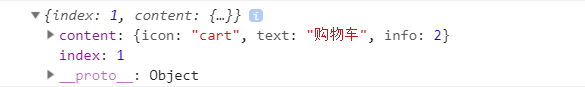


### 5. 提交 goodsdetail 分支

详情页的请求、轮播预览、商品信息、富文本和底部导航核对完成后：

```bash
git add .
git commit -m "完成了商品详情页面的开发"
git push -u origin goodsdetail
git checkout master
git merge goodsdetail
git push
git branch -d goodsdetail
```

合并完成后，继续从 `master` 创建购物车功能分支。


## 六、加入购物车：Vuex 模块与商品数据（8.0—8.4）

### 1. 创建 cart 分支并初始化 Vuex

```bash
git checkout -b cart
```

Vuex 用于在详情页、购物车页和 tabBar 徽标之间共享购物车数据。项目根目录新建 `store` 文件夹，在其中新建 `store.js`。按四步初始化：

```javascript
// 1. 导入 Vue 和 Vuex
import Vue from 'vue'
import Vuex from 'vuex'

// 2. 将 Vuex 安装为 Vue 的插件
Vue.use(Vuex)

// 3. 创建 Store 的实例对象
const store = new Vuex.Store({
  // TODO：挂载 store 模块
  modules: {},
})

// 4. 向外共享 Store 的实例对象
export default store
```

在 `main.js` 导入并挂到 Vue 实例：

```javascript
// 1. 导入 store 的实例对象
import store from './store/store.js'

// 省略其它代码...

const app = new Vue({
  ...App,
  // 2. 将 store 挂载到 Vue 实例上
  store,
})
app.$mount()
```

配套项目的 `main.js` 还保留了 06 的请求拦截器和 `uni.$showMsg()`，最终实例为 `new Vue({ ...App, store })`。

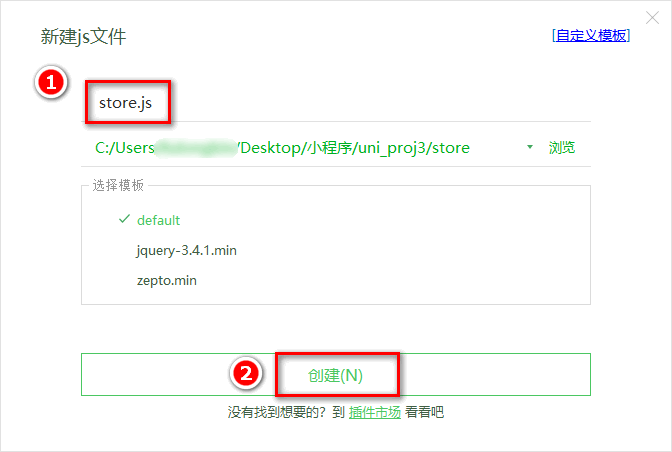


### 2. 创建命名空间为 m_cart 的购物车模块

新建 `store/cart.js`，模块开启命名空间，`state.cart` 保存商品对象数组。每个商品对象固定包含六项：`goods_id`、`goods_name`、`goods_price`、`goods_count`、`goods_small_logo`、`goods_state`。

```javascript
export default {
  // 为当前模块开启命名空间
  namespaced: true,

  // 模块的 state 数据
  state: () => ({
    // 购物车的数组，用来存储购物车中每个商品的信息对象
    // 每个商品的信息对象，都包含如下 6 个属性：
    // { goods_id, goods_name, goods_price, goods_count, goods_small_logo, goods_state }
    cart: [],
  }),

  // 模块的 mutations 方法
  mutations: {},

  // 模块的 getters 属性
  getters: {},
}
```

再在 `store/store.js` 导入并挂载模块：

```javascript
import Vue from 'vue'
import Vuex from 'vuex'
// 1. 导入购物车的 vuex 模块
import moduleCart from './cart.js'

Vue.use(Vuex)

const store = new Vuex.Store({
  // TODO：挂载 store 模块
  modules: {
    // 2. 挂载购物车的 vuex 模块，模块内成员的访问路径被调整为 m_cart，例如：
    //    购物车模块中 cart 数组的访问路径是 m_cart/cart
    m_cart: moduleCart,
  },
})

export default store
```

模块挂载键是 `m_cart`，因此组件中映射 state、getters、mutations 时都要写 `m_cart`。例如购物车数组的访问路径是 `m_cart/cart`。

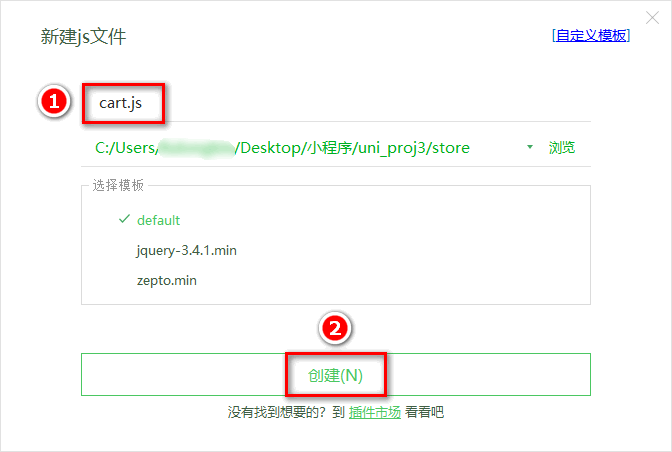


### 3. 在详情页读取 cart

详情页按需导入 `mapState`，把 `m_cart` 模块的 `cart` 映射到计算属性：

```javascript
// 从 vuex 中按需导出 mapState 辅助方法
import { mapState } from 'vuex'

export default {
  computed: {
    // 调用 mapState 方法，把 m_cart 模块中的 cart 数组映射到当前页面中，作为计算属性来使用
    // ...mapState('模块的名称', ['要映射的数据名称1', '要映射的数据名称2'])
    ...mapState('m_cart', ['cart']),
  },
  // 省略其它代码...
}
```

模板中可以直接读取映射后的 `cart`，例如临时显示商品数量：

```html
<!-- 运费 -->
<view class="yf">快递：免运费 -- {{cart.length}}</view>
```

这一步验证 Vuex 数据已挂载，后续会把 `cart.length` 换成所有商品数量的 getter。


### 4. 加入购物车的 mutation 和按钮事件

在 `store/cart.js` 的 `mutations` 中增加 `addToCart(state, goods)`：

```javascript
export default {
  // 为当前模块开启命名空间
  namespaced: true,

  // 模块的 state 数据
  state: () => ({
    // 购物车的数组，用来存储购物车中每个商品的信息对象
    // 每个商品的信息对象，都包含如下 6 个属性：
    // { goods_id, goods_name, goods_price, goods_count, goods_small_logo, goods_state }
    cart: [],
  }),

  // 模块的 mutations 方法
  mutations: {
    addToCart(state, goods) {
      // 根据提交的商品的Id，查询购物车中是否存在这件商品
      // 如果不存在，则 findResult 为 undefined；否则，为查找到的商品信息对象
      const findResult = state.cart.find((x) => x.goods_id === goods.goods_id)

      if (!findResult) {
        // 如果购物车中没有这件商品，则直接 push
        state.cart.push(goods)
      } else {
        // 如果购物车中有这件商品，则只更新数量即可
        findResult.goods_count++
      }
    },
  },

  // 模块的 getters 属性
  getters: {},
}
```

逻辑是按 `goods_id` 查找：购物车没有该商品就 `push`，已有商品只把 `goods_count` 加 1。

详情页通过 `mapMutations` 映射模块 mutation：

```javascript
// 按需导入 mapMutations 这个辅助方法
import { mapMutations } from 'vuex'

export default {
  methods: {
    // 把 m_cart 模块中的 addToCart 方法映射到当前页面使用
    ...mapMutations('m_cart', ['addToCart']),
  },
}
```

点击右侧“加入购物车”时组织完整商品对象，再调用 `this.addToCart(goods)`：

```javascript
// 右侧按钮的点击事件处理函数
buttonClick(e) {
   // 1. 判断是否点击了 加入购物车 按钮
   if (e.content.text === '加入购物车') {

      // 2. 组织一个商品的信息对象
      const goods = {
         goods_id: this.goods_info.goods_id,       // 商品的Id
         goods_name: this.goods_info.goods_name,   // 商品的名称
         goods_price: this.goods_info.goods_price, // 商品的价格
         goods_count: 1,                           // 商品的数量
         goods_small_logo: this.goods_info.goods_small_logo, // 商品的图片
         goods_state: true                         // 商品的勾选状态
      }

      // 3. 通过 this 调用映射过来的 addToCart 方法，把商品信息对象存储到购物车中
      this.addToCart(goods)

   }
}
```

`goods_state: true` 表示商品默认勾选；`goods_count: 1` 表示首次加入一件。此处只更新本地 Vuex，持久化在下一节实现。


## 七、购物车数量、持久化与 tabBar 徽标（8.5—8.9）

### 1. 用 total getter 统计数量

`cart.length` 只能得到商品种类数，不能反映同一商品加入多次后的总件数。在 `store/cart.js` 的 `getters` 中累加 `goods_count`：

```javascript
export default {
  // 模块的 getters 属性
  getters: {
     // 统计购物车中商品的总数量
     total(state) {
        let c = 0
        // 循环统计商品的数量，累加到变量 c 中
        state.cart.forEach(goods => c += goods.goods_count)
        return c
     }
  }
}
```

详情页映射 `total`：

```javascript
// 按需导入 mapGetters 这个辅助方法
import { mapGetters } from 'vuex'

export default {
  computed: {
    // 把 m_cart 模块中名称为 total 的 getter 映射到当前页面中使用
    ...mapGetters('m_cart', ['total']),
  },
}
```

用 `watch` 监听 total，更新导航配置中购物车按钮的 `info`：

```javascript
export default {
  watch: {
    // 1. 监听 total 值的变化，通过第一个形参得到变化后的新值
    total(newVal) {
      // 2. 通过数组的 find() 方法，找到购物车按钮的配置对象
      const findResult = this.options.find((x) => x.text === '购物车')

      if (findResult) {
        // 3. 动态为购物车按钮的 info 属性赋值
        findResult.info = newVal
      }
    },
  },
}
```

这样每次加入商品后，详情页底部购物车按钮的徽标都会跟着变化。


### 2. 把购物车写入本地存储

只放在 Vuex 内存中的数据在重新打开小程序后会丢失。给 `cart.js` 增加 `saveToStorage` mutation：

```javascript
// 将购物车中的数据持久化存储到本地
saveToStorage(state) {
   uni.setStorageSync('cart', JSON.stringify(state.cart))
}
```

在 `addToCart` 完成新增或数量累加后提交它：

```javascript
addToCart(state, goods) {
   // 根据提交的商品的Id，查询购物车中是否存在这件商品
   // 如果不存在，则 findResult 为 undefined；否则，为查找到的商品信息对象
   const findResult = state.cart.find(x => x.goods_id === goods.goods_id)

   if (!findResult) {
      // 如果购物车中没有这件商品，则直接 push
      state.cart.push(goods)
   } else {
      // 如果购物车中有这件商品，则只更新数量即可
      findResult.goods_count++
   }

   // 通过 commit 方法，调用 m_cart 命名空间下的 saveToStorage 方法
   this.commit('m_cart/saveToStorage')
}
```

初始化 state 时从本地读取：

```javascript
export default {
  // 模块的 state 数据
  state: () => ({
     // 购物车的数组，用来存储购物车中每个商品的信息对象
     // 每个商品的信息对象，都包含如下 6 个属性：
     // { goods_id, goods_name, goods_price, goods_count, goods_small_logo, goods_state }
     cart: JSON.parse(uni.getStorageSync('cart') || '[]')
  }),
}
```

`uni.setStorageSync` 保存 JSON 字符串，`uni.getStorageSync` 取回后用 `JSON.parse` 还原数组；没有存储值时使用 `'[]'`，避免解析空字符串报错。


### 3. 用 immediate 让首次加载也更新徽标

普通函数形式的 `watch.total` 只在值变化后触发，详情页第一次加载时可能没有徽标。把侦听器改成对象，在 `handler` 外增加 `immediate: true`：

```javascript
export default {
  watch: {
     // 定义 total 侦听器，指向一个配置对象
     total: {
        // handler 属性用来定义侦听器的 function 处理函数
        handler(newVal) {
           const findResult = this.options.find(x => x.text === '购物车')
           if (findResult) {
              findResult.info = newVal
           }
        },
        // immediate 属性用来声明此侦听器，是否在页面初次加载完毕后立即调用
        immediate: true
     }
  }
}
```

`immediate` 表示侦听器创建后立即执行一次，之后仍继续监听变化。它解决首次进入页面时徽标未显示的问题，数量仍由 `total` getter 计算。


### 4. 在购物车 tabBar 页面设置数字徽标

需求是从详情页切换到购物车页面后，底部 tabBar 的购物车项也显示总件数。先在 `pages/cart/cart.vue` 映射 `m_cart.total`，再在 `onShow` 调用 `setBadge`：

```javascript
// 按需导入 mapGetters 这个辅助方法
import { mapGetters } from 'vuex'

export default {
  data() {
    return {}
  },
  computed: {
    // 将 m_cart 模块中的 total 映射为当前页面的计算属性
    ...mapGetters('m_cart', ['total']),
  },
}
```

在页面生命周期中新增：

```javascript
export default {
  onShow() {
     // 在页面刚展示的时候，设置数字徽标
     this.setBadge()
  }
}
```

`setTabBarBadge` 的 `index: 2` 对应四个 tabBar 中的第三项“购物车”；`text` 必须是字符串，因此使用 `this.total + ''`。

`setBadge` 方法如下：

```javascript
export default {
  methods: {
     setBadge() {
        // 调用 uni.setTabBarBadge() 方法，为购物车设置右上角的徽标
        uni.setTabBarBadge({
           index: 2, // 索引
           text: this.total + '' // 注意：text 的值必须是字符串，不能是数字
        })
     }
  }
}
```

### 5. 抽成 tabbar-badge mixin

如果只在 `cart.vue` 设置徽标，切换到首页、分类、我的时可能不会及时更新。新建 `mixins/tabbar-badge.js`，把 `mapGetters`、`onShow`、`setBadge` 放进可复用对象：

```javascript
import { mapGetters } from 'vuex'

// 导出一个 mixin 对象
export default {
  computed: {
    ...mapGetters('m_cart', ['total']),
  },
  onShow() {
    // 在页面刚展示的时候，设置数字徽标
    this.setBadge()
  },
  methods: {
    setBadge() {
      // 调用 uni.setTabBarBadge() 方法，为购物车设置右上角的徽标
      uni.setTabBarBadge({
        index: 2,
        text: this.total + '', // 注意：text 的值必须是字符串，不能是数字
      })
    },
  },
}
```

四个 tabBar 页面分别导入并混入：

```javascript
// 导入自己封装的 mixin 模块
import badgeMix from '@/mixins/tabbar-badge.js'

export default {
  // 将 badgeMix 混入到当前的页面中进行使用
  mixins: [badgeMix],
  // 省略其它代码...
}
```

最终给 `pages/home/home.vue`、`pages/cate/cate.vue`、`pages/cart/cart.vue`、`pages/my/my.vue` 都加入 `mixins: [badgeMix]`。这样四个页面共享同一套总数计算和徽标设置逻辑。


## 八、第 3 天完成版核对

### 1. 商品详情完成版源码

以下是包内完成版 `subpkg/goods_detail/goods_detail.vue`，包含详情请求、图片预览、富文本处理、底部导航、购物车数量侦听和加入购物车：

```vue
<template>
  <view v-if="goods_info.goods_name" class="goods-detail-container">
    <!-- 轮播图区域 -->
    <swiper :indicator-dots="true" :autoplay="true" :interval="3000" :duration="1000" :circular="true">
      <swiper-item v-for="(item, i) in goods_info.pics" :key="i">
        <image :src="item.pics_big" @click="preview(i)"></image>
      </swiper-item>
    </swiper>

    <!-- 商品信息区域 -->
    <view class="goods-info-box">
      <!-- 商品价格 -->
      <view class="price">￥{{goods_info.goods_price}}</view>
      <!-- 商品信息主体区域 -->
      <view class="goods-info-body">
        <!-- 商品的名字 -->
        <view class="goods-name">{{goods_info.goods_name}}</view>
        <!-- 收藏 -->
        <view class="favi">
          <uni-icons type="star" size="18" color="gray"></uni-icons>
          <text>收藏</text>
        </view>
      </view>
      <!-- 运费 -->
      <view class="yf">快递：免运费</view>
    </view>

    <rich-text :nodes="goods_info.goods_introduce"></rich-text>

    <!-- 商品导航组件区域 -->
    <view class="goods_nav">
      <uni-goods-nav :fill="true" :options="options" :buttonGroup="buttonGroup" @click="onClick" @buttonClick="buttonClick" />
    </view>
  </view>
</template>

<script>
  import { mapState, mapMutations, mapGetters } from 'vuex'

  export default {
    computed: {
      ...mapState('m_cart', []),
      ...mapGetters('m_cart', ['total'])
    },
    watch: {
      // total(newVal) {
      //   const findResult = this.options.find(x => x.text === '购物车')
      //   if (findResult) {
      //     findResult.info = newVal
      //   }
      // }
      total: {
        handler(newVal) {
          const findResult = this.options.find(x => x.text === '购物车')
          if (findResult) {
            findResult.info = newVal
          }
        },
        immediate: true
      }
    },
    data() {
      return {
        goods_info: {},
        options: [{
          icon: 'shop',
          text: '店铺',
          infoBackgroundColor: '#007aff',
          infoColor: "red"
        }, {
          icon: 'cart',
          text: '购物车',
          info: 0
        }],
        buttonGroup: [{
            text: '加入购物车',
            backgroundColor: '#ff0000',
            color: '#fff'
          },
          {
            text: '立即购买',
            backgroundColor: '#ffa200',
            color: '#fff'
          }
        ]
      };
    },
    onLoad(options) {
      const goods_id = options.goods_id
      this.getGoodsDetail(goods_id)
    },
    methods: {
      ...mapMutations('m_cart', ['addToCart']),
      async getGoodsDetail(goods_id) {
        const { data: res } = await uni.$http.get('/api/public/v1/goods/detail', { goods_id })
        if (res.meta.status !== 200) return uni.$showMsg()

        res.message.goods_introduce = res.message.goods_introduce.replace(/<img /g, '<img style="display:block;" ').replace(/webp/g, 'jpg')

        this.goods_info = res.message

        // <img style=\"display:block;\" data-src=\"//image.suning.cn/uimg/sop/commodity/966602987133443585157120_x.jpg?from=mobile&amp;format=80q.webp\" alt=\"\" src=\"//image.suning.cn/uimg/sop/commodity/966602987133443585157120_x.jpg?from=mobile&format=80q.webp\" width=\"100%\" height=\"auto\">
      },
      preview(i) {
        uni.previewImage({
          current: i,
          urls: this.goods_info.pics.map(x => x.pics_big)
        })
      },
      onClick(e) {
        if (e.content.text === '购物车') {
          uni.switchTab({
            url: '/pages/cart/cart'
          })
        }
      },
      buttonClick(e) {
        if (e.content.text === '加入购物车') {
          // 组织商品的信息对象
          // { goods_id, goods_name, goods_price, goods_count, goods_small_logo, goods_state }
          const goods = {
            goods_id: this.goods_info.goods_id,
            goods_name: this.goods_info.goods_name,
            goods_price: this.goods_info.goods_price,
            goods_count: 1,
            goods_small_logo: this.goods_info.goods_small_logo,
            goods_state: true
          }

          // 调用 addToCart 方法
          this.addToCart(goods)
        }
      }
    }
  }
</script>

<style lang="scss">
  swiper {
    height: 750rpx;

    image {
      width: 100%;
      height: 100%;
    }
  }

  .goods-info-box {
    padding: 10px;
    padding-right: 0;

    .price {
      color: #C00000;
      font-size: 18px;
      margin: 10px 0;
    }

    .goods-info-body {
      display: flex;
      justify-content: space-between;

      .goods-name {
        font-size: 13px;
        margin-right: 10px;
      }

      .favi {
        width: 120px;
        font-size: 12px;
        display: flex;
        flex-direction: column;
        align-items: center;
        justify-content: center;
        border-left: 1px solid #efefef;
        color: gray;
      }
    }

    .yf {
      font-size: 12px;
      color: gray;
      margin: 10px 0;
    }
  }

  .goods_nav {
    position: fixed;
    bottom: 0;
    left: 0;
    width: 100%;
  }

  .goods-detail-container {
    padding-bottom: 50px;
  }
</style>
```


### 2. Store、mixins 与页面配置

`store/store.js` 负责创建 Vuex 实例并挂载 `m_cart`，包内完成版如下。源码使用 `@/` 表示项目根目录，前文讲义用相对路径，均指向同一个 `cart.js`：

```javascript
import Vue from 'vue'
import Vuex from 'vuex'
import moduleCart from '@/store/cart.js'

Vue.use(Vuex)

const store = new Vuex.Store({
  modules: {
    // 挂载购物车的 vuex 模块，模块内成员的访问路径被调整为 m_cart，例如：
    // 购物车模块中 cart 数组的访问路径是 m_cart/cart
    'm_cart': moduleCart
  }
})

export default store
```


`store/cart.js` 完成版把商品合并、数量统计和本地存储放在同一个模块中：

```javascript
export default {
  namespaced: true,

  state: () => ({
    // 购物车的数组，用来存储购物车中每个商品的信息对象
    // 每个商品的信息对象，都包含如下 6 个属性：
    // { goods_id, goods_name, goods_price, goods_count, goods_small_logo, goods_state }
    cart: JSON.parse(uni.getStorageSync('cart') || '[]')
  }),

  mutations: {
    addToCart(state, goods) {
      const findResult = state.cart.find(x => x.goods_id === goods.goods_id)

      if (!findResult) {
        state.cart.push(goods)
      } else {
        findResult.goods_count++
      }
      
      this.commit('m_cart/saveToStorage')
    },
    saveToStorage(state) {
      uni.setStorageSync('cart', JSON.stringify(state.cart))
    }
  },

  getters: {
    total(state) {
      let c = 0
      state.cart.forEach(x => c += x.goods_count)
      return c
    }
  }
}
```


`mixins/tabbar-badge.js` 完成版：

```javascript
import { mapGetters } from 'vuex'

export default {
  computed: {
    ...mapGetters('m_cart', ['total'])
  },
  onShow() {
    this.setBadge()
  },
  methods: {
    setBadge() {
      uni.setTabBarBadge({
        index: 2,
        text: this.total + ''
      })
    }
  }
}
```


`main.js` 中沿用网络请求配置，导入 `store` 并挂到实例的完整代码如下：

```javascript
import Vue from 'vue'
import App from './App'
import store from '@/store/store.js'

// 导入网络请求的包
import { $http } from '@escook/request-miniprogram'

uni.$http = $http

// 请求的根路径
$http.baseUrl = 'https://www.uinav.com'

// 请求拦截器
$http.beforeRequest = function(options) {
  uni.showLoading({
    title: '数据加载中...'
  })
}

// 响应拦截器
$http.afterRequest = function() {
  uni.hideLoading()
}

// 封装弹框的方法
uni.$showMsg = function(title = '数据请求失败！', duration = 1500) {
  uni.showToast({
    title,
    duration,
    icon: 'none'
  })
}

Vue.config.productionTip = false

App.mpType = 'app'

const app = new Vue({
  ...App,
  store
})
app.$mount()
```


四个 tabBar 页面都已引入上述 mixin，包内 `pages/cart/cart.vue` 仍是基本占位页：

```vue
<template>
  <view>
    Cart
  </view>
</template>

<script>
  import badgeMix from '@/mixins/tabbar-badge.js'

  export default {
    mixins: [badgeMix],
    data() {
      return {

      };
    }
  }
</script>

<style lang="scss">

</style>
```


`pages.json` 中商品列表页面最终配置如下：

```json
{
  "path": "goods_list/goods_list",
  "style": {
    "onReachBottomDistance": 150,
    "enablePullDownRefresh": true,
    "backgroundColor": "#F8F8F8"
  }
}
```


### 3. 本天验证点

| 操作 | 应看到的效果 |
| --- | --- |
| 用 `cid=5` 编译商品列表 | 列表加载分类商品，缺图时显示默认图片 |
| 滚动到距离底部 150px | 追加下一页，不覆盖已有商品 |
| 连续快速触底 | `isloading` 阻止重复请求 |
| 继续滚动到最后一页 | 提示“数据加载完毕！” |
| 下拉列表 | 清空旧数据，从第 1 页重新加载并停止刷新动画 |
| 点击商品 | 打开详情分包页并携带 `goods_id` |
| 点击详情图 | 从当前图片开始预览全部大图 |
| 查看商品介绍 | `rich-text` 渲染 HTML，图片无底部空隙 |
| 点击加入购物车 | 相同商品数量累加，不同商品新增 |
| 重新打开页面 | 购物车从本地存储恢复 |
| 切换四个 tabBar 页面 | 购物车项显示总件数徽标 |

本天完成商品列表、商品详情和加入购物车。购物车列表页面的商品勾选、合计金额、结算等属于后续内容，本篇不提前实现。

项目第 3 天讲义到 8.9 的 mixins 为止，购物车功能继续在 `cart` 分支开发。本篇展示的是包内工作目录的源码，已检查笔记 JSON、Notebook 格式、代码围栏和静态 JavaScript 语法；没有在微信开发者工具中实际运行，上表是跟课时应检查的效果。
